# 01 — Exploratory Data Analysis & Solar Physics Feature Engineering (V2)

This notebook demonstrates the **out-of-core Polars + `pvlib` ETL pipeline** on the anonymized 15-minute hybrid microgrid dataset (`data/sample/microgrid_sample_15min.parquet`).

**Pipeline Stages:**
1. Operational state masking (`edge_offline_alarm == 1` → `null`; night `ghi_w_m2 == 0` → `0.0 kW`) and physical telemetry clipping.
2. NREL astronomical solar geometry & isotropic Plane-of-Array (`poa_global`) irradiance transposition via `pvlib`.
3. Causal feature engineering: normalized `capacity_factor`, 15m/1h/24h site-grouped lags, rain-wash dust attenuation (`days_since_rain`), and inverter `curtailment_state`.
4. Pre-modeling Data Health Scorecard and daytime Gold matrix export.

In [1]:
from pathlib import Path
import sys
import polars as pl

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from microgrid_ml.config import load_config
from microgrid_ml.data.etl_polars import run_etl_pipeline
from microgrid_ml.visualization.plots import (
    plot_capacity_factor_distribution,
    plot_correlation_matrix,
)

cfg = load_config(repo_root=REPO_ROOT)
raw_df = pl.read_parquet(cfg.sample_raw_parquet)
print(f"Raw sample shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns | Sites: {raw_df['site_id'].n_unique()}")
raw_df.select(["site_id", "region_zone", "topology", "time_local_dt", "solar_power_kw", "load_power_kw", "battery_soc_pct"]).head(5)

Raw sample shape: 242,880 rows x 31 columns | Sites: 10


site_id,region_zone,topology,time_local_dt,solar_power_kw,load_power_kw,battery_soc_pct
cat,cat,cat,datetime[ns],f32,f32,f32
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",2025-12-31 21:00:00,0.0,0.930466,89.224556
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",2025-12-31 21:15:00,0.0,0.823479,88.327759
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",2025-12-31 21:30:00,0.0,0.779761,87.478577
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",2025-12-31 21:45:00,0.0,0.92085,86.475739
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",2025-12-31 22:00:00,0.0,0.86689,85.53167


In [2]:
df_gold, scorecard = run_etl_pipeline(cfg)

print("=== DATA HEALTH SCORECARD ===")
print(f"Valid rows before daytime filter: {scorecard.total_rows:,}")
print(f"Day / Night split:                {scorecard.daytime_rows:,} / {scorecard.nighttime_rows:,}")
print(f"Night zero-kW integrity:          {scorecard.night_zero_integrity_pct:.2f}%")
print(f"15-min lag continuity:            {scorecard.continuous_15m_pct:.2f}% (gaps: {scorecard.time_gap_rows:,})")
print(f"Dormant sites excluded (<5% CF):  {scorecard.dormant_sites}")
print(f"Gold daytime ML matrix:           {df_gold.height:,} rows x {df_gold.width} columns")

=== DATA HEALTH SCORECARD ===
Valid rows before daytime filter: 223,293
Day / Night split:                105,500 / 117,793
Night zero-kW integrity:          94.38%
15-min lag continuity:            91.94% (gaps: 17,993)
Dormant sites excluded (<5% CF):  0
Gold daytime ML matrix:           108,475 rows x 50 columns


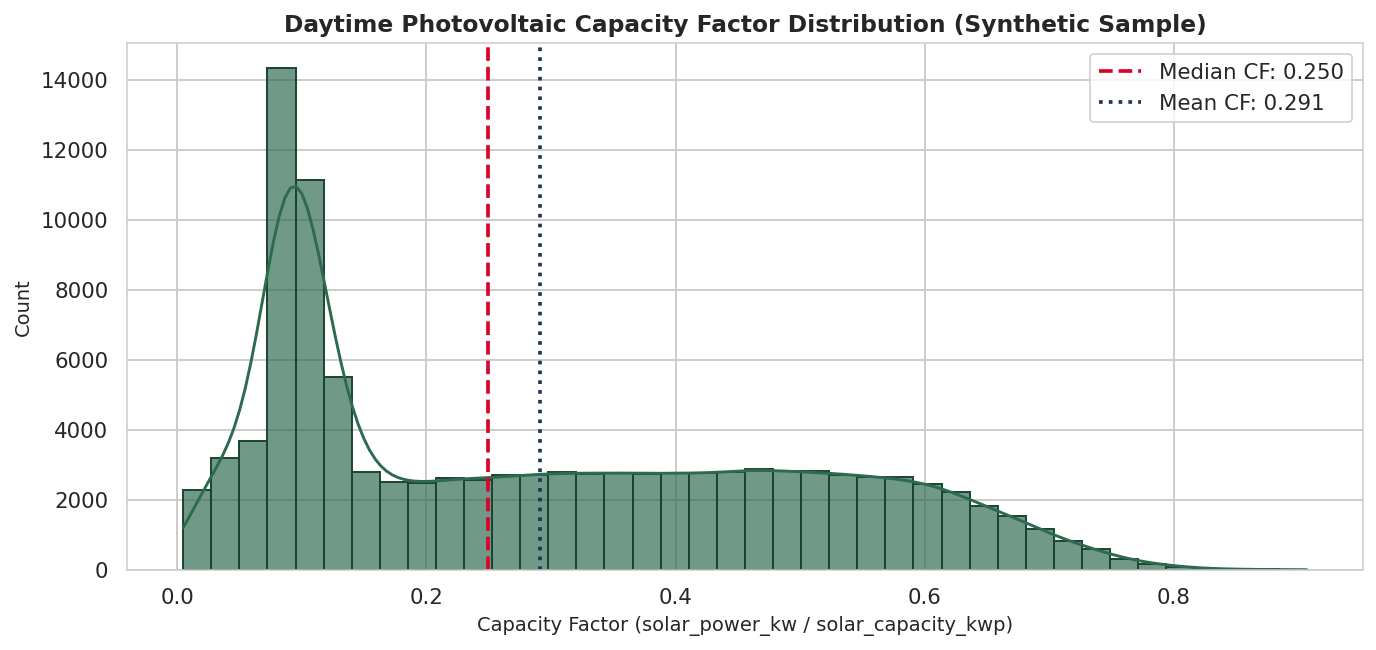

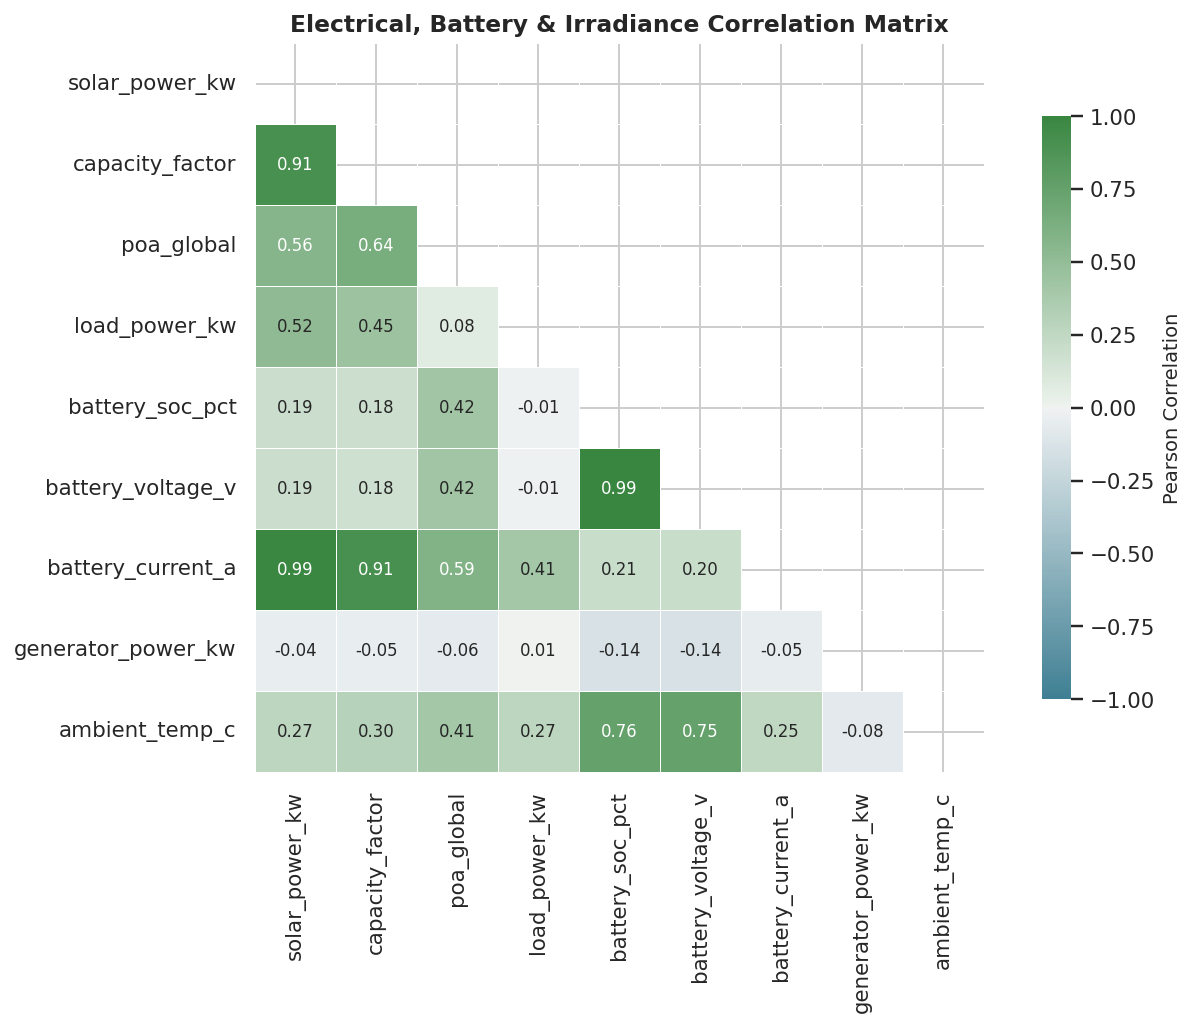

In [3]:
from IPython.display import Image, display

cf_fig = plot_capacity_factor_distribution(df_gold, cfg.figures_dir / "capacity_factor_distribution.png")
corr_fig = plot_correlation_matrix(df_gold, cfg.figures_dir / "correlation_matrix.png")

display(Image(filename=str(cf_fig)))
display(Image(filename=str(corr_fig)))